<a href="https://colab.research.google.com/github/willismax/MediaSystem-Python-Course/blob/main/13.Image-Processing/Late_Prompt_Reproducibility_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07｜潛在空間、提示控制與可重現比較

歡迎來到《多媒體系統：從資料原理到 AI 協作》第七章實驗室！
在上一章我們認識了 Diffusion 從隨機雜訊（Random Noise）逐步去噪的過程。本章我們要進一步解開三個關鍵的工程問題：

1. **為什麼不直接在 Pixel Space 算？** $\rightarrow$ 認識 **Latent Space（潛在空間）**、Encoder 與 Decoder 的算力節省機制。
2. **文字（Prompt）怎麼影響圖片？** $\rightarrow$ 認識 **Conditioning（條件控制）**、Cross-Attention 與 **CFG（Classifier-Free Guidance）**。
3. **生成式 AI 充滿隨機性，怎麼做公平的科學實驗？** $\rightarrow$ 建立 **控制變因（Four-grid Comparison）**、**Generation Manifest（實驗紀錄 JSON）**、**Experiment Hash 快取** 與 **Exponential Backoff 批次防禦**。

---

### 🧠 核心架構圖：Latent Diffusion 與條件控制

```text
[Prompt 文字] ──> [Tokenizer / Text Encoder] ──> [Text Condition (條件向量)]
                                                        │ (透過 Cross-Attention 注入)
                                                        ▼
[Random Seed] ──> [Latent Noise (低維度)] ──────> [Denoising Loop (反覆去噪)] ──> [Generated Latent] ──> [Decoder] ──> [RGB Image]
```

> 📌 **本章最重要的三個工程觀念**：
> 1. **Prompt 是 Condition，不是魔法咒語**：需要控制什麼（主體、特徵、環境、構圖、光線、風格），就把什麼說清楚，不必迷信 `8k, masterpiece` 等 Quality Words。
> 2. **同 Seed $\neq$ 絕對同圖**：固定 Seed 可控制隨機起點，但完整重現還受 Model Revision、Scheduler、Steps、CFG、硬體與函式庫版本影響。
> 3. **一次只改一個主要變因**：沒有固定其他條件、沒有留下 Generation Manifest，就無法合理下結論。

In [3]:
# @title Step 0｜一鍵初始化實驗環境、目錄結構與教學生成沙盒 (Zero-Setup) { display-mode: "form" }
# @markdown 請先執行此區塊！它會自動建立 `experiment_07/` 標準資料夾結構，並載入「教學用條件生成模擬引擎」與「Contact Sheet 自動排版工具」（免 API Key、免 GPU 即可 100% 完成所有控制變因實驗！）。

import os
import json
import time
import shutil
import hashlib
from datetime import datetime
from pathlib import Path
import numpy as np
from PIL import Image, ImageDraw, ImageFont, ImageFilter, ImageEnhance
import matplotlib.pyplot as plt

# 1. 建立教材 7.25 規範的標準實驗資料夾結構
EXP_ROOT = Path("experiment_07")
PROMPTS_DIR = EXP_ROOT / "prompts"
OUTPUTS_DIR = EXP_ROOT / "outputs"
METADATA_DIR = EXP_ROOT / "metadata"

for d in [PROMPTS_DIR, OUTPUTS_DIR, METADATA_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 預先寫入教材 7.16 的 Prompt Version 檔案
PROMPT_VERSIONS = {
    "V1": "a corgi wearing a graduation cap",
    "V2": "a corgi wearing a graduation cap, sitting in front of a university library",
    "V3": "a corgi wearing a red graduation cap, sitting in front of a university library, centered composition, eye-level camera, soft afternoon light, flat editorial illustration",
    "V4": "a corgi wearing a red graduation cap, sitting in front of a university library, centered composition, soft afternoon light, holding a sign with text 'CLASS OF 2026'"
}

for ver, text in PROMPT_VERSIONS.items():
    (PROMPTS_DIR / f"prompt_{ver.lower()}.txt").write_text(text, encoding="utf-8")

# 2. 教學用「條件擴散模擬生成引擎」 (Procedural Conditional Diffusion Simulator)
# 能夠真實反映 Seed (隨機位置/雲朵/書籍排列)、Prompt 條件 (場景/紅帽/光線/構圖) 與 Guidance Scale (過低模糊偏離、過高過飽和破圖)
def simulate_conditional_generation(config: dict) -> Image.Image:
    w = config.get("width", 512)
    h = config.get("height", 512)
    seed = int(config.get("seed", 42))
    prompt = config.get("prompt", "").lower()
    cfg = float(config.get("guidance_scale", 7.0))
    steps = int(config.get("steps", 30))

    rng = np.random.default_rng(seed)

    # 根據 Prompt 判斷條件是否啟用
    has_library = "library" in prompt or "campus" in prompt or "university" in prompt
    has_afternoon = "afternoon" in prompt or "warm" in prompt or "sunset" in prompt
    has_centered = "centered" in prompt
    has_cap = "cap" in prompt or "hat" in prompt
    is_red_cap = "red" in prompt and has_cap
    has_sign = "sign" in prompt or "text" in prompt or "2026" in prompt

    # 當 CFG 極低 (< 2.5) 時，模型不太聽從 Prompt 條件 (Unconditional 佔主導)
    condition_strength = np.clip((cfg - 1.0) / 6.0, 0.0, 1.5)

    # 建立背景漸層
    y_grid, x_grid = np.mgrid[0:h, 0:w].astype(np.float32)
    canvas = np.zeros((h, w, 3), dtype=np.float32)

    if has_afternoon and condition_strength > 0.4:
        # 溫暖午後色調
        sky_top = np.array([245, 190, 120])
        sky_bot = np.array([255, 235, 195])
    else:
        # 一般隨機天空色調 (受 Seed 影響微調)
        hue_shift = rng.integers(-20, 20, size=3)
        sky_top = np.clip(np.array([135, 185, 235]) + hue_shift, 40, 250)
        sky_bot = np.clip(np.array([215, 235, 250]) + hue_shift, 40, 250)

    for c in range(3):
        canvas[:, :, c] = sky_top[c] * (1 - y_grid / h) + sky_bot[c] * (y_grid / h)

    img = Image.fromarray(canvas.astype(np.uint8))
    draw = ImageDraw.Draw(img)

    # 地面草皮或廣場
    horizon_y = int(h * 0.68)
    ground_color = (120, 165, 110) if not has_afternoon else (155, 165, 105)
    draw.rectangle([0, horizon_y, w, h], fill=ground_color)

    # 隨機種子控制的背景雲朵或光斑
    for _ in range(5):
        cx = int(rng.integers(30, w - 30))
        cy = int(rng.integers(30, int(h * 0.45)))
        cr = int(rng.integers(20, 50))
        draw.ellipse([cx - cr*1.5, cy - cr*0.6, cx + cr*1.5, cy + cr*0.6], fill=(250, 250, 245))

    # 條件：大學圖書館背景 (University Library)
    if has_library and condition_strength > 0.35:
        lib_w, lib_h = int(w * 0.76), int(h * 0.42)
        lib_x = (w - lib_w) // 2 + (0 if has_centered else int(rng.integers(-35, 35)))
        lib_y = horizon_y - lib_h
        # 建築主體與屋頂
        draw.rectangle([lib_x, lib_y, lib_x + lib_w, horizon_y], fill=(215, 200, 185), outline=(140, 125, 110), width=3)
        draw.polygon([(lib_x - 15, lib_y), (lib_x + lib_w // 2, lib_y - 45), (lib_x + lib_w + 15, lib_y)], fill=(165, 95, 80))
        # 圖書館柱子與窗戶
        num_cols = 4
        col_spacing = lib_w // (num_cols + 1)
        for i in range(1, num_cols + 1):
            cx = lib_x + i * col_spacing
            draw.rectangle([cx - 8, lib_y + 15, cx + 8, horizon_y], fill=(240, 235, 225), outline=(170, 160, 150))

    # 決定主角 Corgi 的位置 (是否 centered composition，否則隨 Seed 偏移)
    if has_centered and condition_strength > 0.5:
        dog_x = w // 2
    else:
        dog_x = w // 2 + int(rng.integers(-int(w * 0.22), int(w * 0.22)))
    dog_y = int(h * 0.66)

    # 當 CFG > 1.5 時繪製柯基犬主體
    if condition_strength > 0.15 and "corgi" in prompt:
        fur_color = (225, 145, 65)
        white_fur = (250, 245, 238)
        # 身體與白胸毛
        draw.ellipse([dog_x - 65, dog_y - 25, dog_x + 65, dog_y + 75], fill=fur_color, outline=(120, 70, 20), width=3)
        draw.ellipse([dog_x - 38, dog_y - 10, dog_x + 38, dog_y + 70], fill=white_fur)
        # 耳朵 (隨 Seed 稍微擺動角度)
        ear_jitter = int(rng.integers(-12, 12))
        draw.polygon([(dog_x - 52, dog_y - 65), (dog_x - 75, dog_y - 135 + ear_jitter), (dog_x - 18, dog_y - 90)], fill=fur_color, outline=(120, 70, 20))
        draw.polygon([(dog_x + 52, dog_y - 65), (dog_x + 75, dog_y - 135 - ear_jitter), (dog_x + 18, dog_y - 90)], fill=fur_color, outline=(120, 70, 20))
        # 頭部
        draw.ellipse([dog_x - 58, dog_y - 105, dog_x + 58, dog_y - 5], fill=fur_color, outline=(120, 70, 20), width=3)
        draw.ellipse([dog_x - 22, dog_y - 65, dog_x + 22, dog_y - 12], fill=white_fur)
        # 眼睛與鼻子
        draw.ellipse([dog_x - 32, dog_y - 70, dog_x - 18, dog_y - 56], fill=(30, 25, 20))
        draw.ellipse([dog_x + 18, dog_y - 70, dog_x + 32, dog_y - 56], fill=(30, 25, 20))
        draw.ellipse([dog_x - 9, dog_y - 45, dog_x + 9, dog_y - 31], fill=(35, 30, 30))

        # 條件：畢業帽 (Graduation Cap)
        if has_cap and condition_strength > 0.25:
            cap_color = (200, 35, 40) if is_red_cap else (40, 45, 60)
            # 帽頂菱形
            draw.polygon([
                (dog_x, dog_y - 140),
                (dog_x - 68, dog_y - 115),
                (dog_x, dog_y - 92),
                (dog_x + 68, dog_y - 115)
            ], fill=cap_color, outline=(25, 25, 25))
            # 流蘇
            tassel_side = -1 if rng.random() > 0.5 else 1
            draw.line([(dog_x, dog_y - 115), (dog_x + tassel_side * 48, dog_y - 80)], fill=(245, 205, 50), width=4)

        # 條件：手舉牌文字 (模擬 AI 文字渲染可能產生的拼字誤差 vs Pillow 精確排版)
        if has_sign and condition_strength > 0.4:
            draw.rectangle([dog_x - 75, dog_y + 45, dog_x + 75, dog_y + 92], fill=(255, 252, 240), outline=(80, 60, 40), width=2)
            # 模擬生成模型偶爾出現的文字變異
            rendered_txt = "CLASS OF 2026" if seed % 2 == 0 else "CL4SS 0F 202G"
            draw.text((dog_x - 52, dog_y + 62), rendered_txt, fill=(40, 40, 40))

    # 模擬 Denoising Steps 不足時的殘留雜訊
    if steps < 20:
        arr = np.asarray(img).astype(np.float32)
        noise_level = (20 - steps) * 6.5
        arr += rng.normal(0, noise_level, arr.shape)
        img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

    # 模擬 Guidance Scale (CFG) 極端值的現象
    if cfg <= 2.0:
        # CFG 過低：缺乏條件引導，結構鬆散模糊、對比低
        img = img.filter(ImageFilter.GaussianBlur(radius=3.5))
        img = ImageEnhance.Color(img).enhance(0.45)
    elif cfg >= 12.0:
        # CFG 過高：色彩過度飽和、邊緣銳化破圖 (Artifacts / Deep-fried effect)
        over_factor = 1.0 + (cfg - 10.0) * 0.35
        img = ImageEnhance.Contrast(img).enhance(over_factor)
        img = ImageEnhance.Color(img).enhance(over_factor * 1.2)
        img = ImageEnhance.Sharpness(img).enhance(over_factor * 1.5)

    return img

print("✅ 環境初始化完成！")
print(f"📂 實驗根目錄：{EXP_ROOT.resolve()}")
print("   ├─ prompts/   (已寫入 V1 ~ V4 提示詞版本)")
print("   ├─ outputs/   (存放生成圖片與 Contact Sheet)")
print("   └─ metadata/  (存放每張圖對應的 Generation Manifest JSON)")

✅ 環境初始化完成！
📂 實驗根目錄：/content/experiment_07
   ├─ prompts/   (已寫入 V1 ~ V4 提示詞版本)
   ├─ outputs/   (存放生成圖片與 Contact Sheet)
   └─ metadata/  (存放每張圖對應的 Generation Manifest JSON)


In [4]:
# @title Step 0｜安裝套件並初始化「真實 Latent Diffusion 生成引擎」 { display-mode: "form" }
# @markdown 執行此區塊將會安裝 Hugging Face `diffusers`，並建立 `experiment_07/` 實驗資料夾結構。
# @markdown > 💡 **提醒**：請確認 Colab 上方選單「執行階段 > 變更執行階段類型」已選擇 **T4 GPU**（若無 GPU 也可切換為「雲端真實 AI API 模式」）。

!pip install -q -U diffusers transformers accelerate safetensors

import os
import json
import time
import hashlib
import requests
from io import BytesIO
from datetime import datetime
from pathlib import Path
import numpy as np
import torch
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# 1. 建立教材 7.25 標準實驗資料夾
EXP_ROOT = Path("experiment_07")
PROMPTS_DIR = EXP_ROOT / "prompts"
OUTPUTS_DIR = EXP_ROOT / "outputs"
METADATA_DIR = EXP_ROOT / "metadata"

for d in [PROMPTS_DIR, OUTPUTS_DIR, METADATA_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 2. 寫入教材 7.16 的 Prompt Versions
PROMPT_VERSIONS = {
    "V1": "a corgi wearing a graduation cap",
    "V2": "a corgi wearing a graduation cap, sitting in front of a university library",
    "V3": "a corgi wearing a red graduation cap, sitting in front of a university library, centered composition, eye-level camera, soft afternoon light, flat editorial illustration",
    "V4": "a corgi wearing a red graduation cap, sitting in front of a university library, centered composition, soft afternoon light, high quality digital art"
}

for ver, text in PROMPT_VERSIONS.items():
    (PROMPTS_DIR / f"prompt_{ver.lower()}.txt").write_text(text, encoding="utf-8")

# 3. 計算教材 7.23 的 Experiment Hash
def make_experiment_hash(config: dict) -> str:
    core_keys = [
        "model", "revision", "prompt", "negative_prompt",
        "seed", "width", "height", "steps", "scheduler", "guidance_scale"
    ]
    filtered = {k: config.get(k) for k in core_keys}
    text = json.dumps(filtered, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:12]

# 4. 全域 Pipeline 快取（避免重複載入模型）
_GLOBAL_PIPE = None
_CURRENT_MODEL_ID = None

def get_diffusion_pipe(model_id: str = "runwayml/stable-diffusion-v1-5"):
    global _GLOBAL_PIPE, _CURRENT_MODEL_ID
    if _GLOBAL_PIPE is None or _CURRENT_MODEL_ID != model_id:
        from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler
        device = "cuda" if torch.cuda.is_available() else "cpu"
        dtype = torch.float16 if device == "cuda" else torch.float32
        print(f"⏳ 正在載入真實 Latent Diffusion 模型：{model_id} (Device: {device}, Dtype: {dtype})...")
        pipe = StableDiffusionPipeline.from_pretrained(
            model_id,
            torch_dtype=dtype,
            safety_checker=None
        )
        pipe.scheduler = EulerDiscreteScheduler.from_config(pipe.scheduler.config)
        pipe = pipe.to(device)
        _GLOBAL_PIPE = pipe
        _CURRENT_MODEL_ID = model_id
        print("✅ 模型載入完成！包含 Text Encoder (CLIP)、UNet (Cross-Attention) 與 VAE (Encoder/Decoder)。")
    return _GLOBAL_PIPE

device_status = "🚀 偵測到 CUDA GPU (可高速執行本地 Latent Diffusion！)" if torch.cuda.is_available() else "⚠️ 目前為 CPU 環境 (建議切換至 T4 GPU，或在下一步選擇『雲端真實 AI 生成』)"
print(f"\n環境準備完成！{device_status}")


環境準備完成！🚀 偵測到 CUDA GPU (可高速執行本地 Latent Diffusion！)


In [5]:
# @title Step 0｜Colab 進行matplotlib繪圖時顯示繁體中文
# @markdown 下載台北思源黑體並命名taipei_sans_tc_beta.ttf，移至指定路徑
!wget -O TaipeiSansTCBeta-Regular.ttf https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download

import matplotlib

# 改style要在改font之前
# plt.style.use('seaborn')

matplotlib.font_manager.fontManager.addfont('TaipeiSansTCBeta-Regular.ttf')
matplotlib.rc('font', family='Taipei Sans TC Beta')

--2026-10-21 08:09:04--  https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.google.com (drive.google.com)... 172.217.79.138, 172.217.79.139, 172.217.79.101, ...
Connecting to drive.google.com (drive.google.com)|172.217.79.138|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_ [following]
--2026-10-21 08:09:04--  https://drive.usercontent.google.com/download?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.218.132, 2a00:1450:4013:c08::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.218.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 20659344 (20M) [application/octet-stream]
Saving to: ‘TaipeiSansTCBeta-Regular.ttf’

TaipeiSansTCBeta-Re 100%[===================>]  19.70M  --.-KB/s    in 0.1s    

2026-10-21 08:0

---
## Lab 1｜為什麼不直接在完整 Pixel Space 生成？（7.1 ～ 7.3 & 7.9）

假設一張 RGB 圖片尺寸是 `1024 × 1024`，光是單張圖片的 Pixel 數值就有：
$$1024 \times 1024 \times 3 = 3,145,728 \text{ 個數值}$$

Latent Diffusion Models（LDM）透過 **Encoder** 先將圖片映射到較緊湊的 **Latent Space**（例如長寬縮小 8 倍、4 個 Channels：$128 \times 128 \times 4 = 65,536$ 個數值），在 Latent Space 中完成數十步的 Denoising 與 Cross-Attention 運算後，最後才由 **Decoder** 轉回 RGB 圖片。

> ⚠️ **觀念釐清（7.2）**：Latent Space **不是「縮小版 JPEG」**，也不是單純 `resize(128, 128)`，更不能把單一 Channel 解讀為「Channel 1 = 人臉、Channel 2 = 風格」。它是模型學會的緊湊內部表示。

請執行下方互動實驗，觀察 **Pixel vs. Latent 的運算量差距**，以及 **CFG 公式 $\hat{\epsilon} = \epsilon_{\text{uncond}} + s(\epsilon_{\text{cond}} - \epsilon_{\text{uncond}})$** 的方向放大效應！

📊 【解析度 1024x1024 下的單步張量規模與 50 步累積運算比較】
  • Pixel Space 張量形狀  : (1024, 1024, 3)  --> 單步  3,145,728 個數值
  • Latent Space 張量形狀 : (128, 128, 4)    --> 單步     65,536 個數值
  • 資料維度縮減倍率      : 整整少了 48.0 倍！
  • 執行 50 步總處理元素量 : Pixel 需處理 157,286,400 vs. Latent 僅需 3,276,800


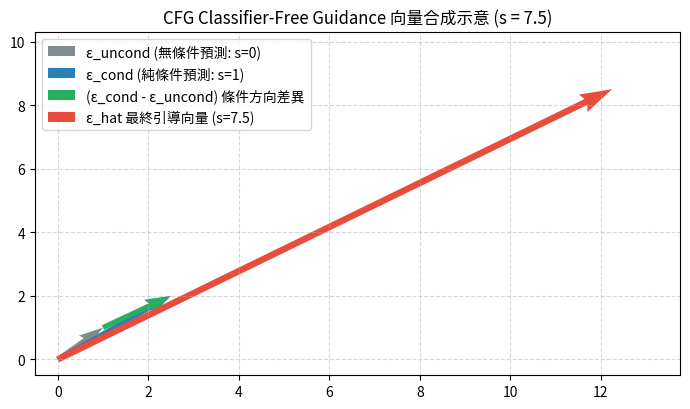

In [6]:
# @title Lab 1｜Pixel vs. Latent 算力比較 ＆ CFG 條件引導向量視覺化 { display-mode: "form" }
圖片解析度 = 1024 # @param [512, 1024, 2048] {type:"raw"}
去噪步數_Steps = 50 # @param {type:"slider", min:10, max:100, step:10}
CFG_Guidance_Scale = 7.5 # @param {type:"slider", min:0.0, max:20.0, step:0.5}

# 1. 計算 Pixel Space vs Latent Space (以常見 8x 下取樣、4 channels 為例)
pixel_elements = 圖片解析度 * 圖片解析度 * 3
latent_h, latent_w, latent_c = 圖片解析度 // 8, 圖片解析度 // 8, 4
latent_elements = latent_h * latent_w * latent_c
ratio = pixel_elements / latent_elements

print("=" * 65)
print(f"📊 【解析度 {圖片解析度}x{圖片解析度} 下的單步張量規模與 {去噪步數_Steps} 步累積運算比較】")
print("=" * 65)
print(f"  • Pixel Space 張量形狀  : ({圖片解析度}, {圖片解析度}, 3)  --> 單步 {pixel_elements:>10,} 個數值")
print(f"  • Latent Space 張量形狀 : ({latent_h}, {latent_w}, {latent_c})    --> 單步 {latent_elements:>10,} 個數值")
print(f"  • 資料維度縮減倍率      : 整整少了 {ratio:.1f} 倍！")
print(f"  • 執行 {去噪步數_Steps} 步總處理元素量 : Pixel 需處理 {pixel_elements * 去噪步數_Steps:,} vs. Latent 僅需 {latent_elements * 去噪步數_Steps:,}")
print("=" * 65)

# 2. 視覺化 CFG 公式：e_hat = e_uncond + s * (e_cond - e_uncond)
e_uncond = np.array([1.0, 1.0])
e_cond = np.array([2.5, 2.0])
diff = e_cond - e_uncond
e_hat = e_uncond + CFG_Guidance_Scale * diff

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.quiver(0, 0, e_uncond[0], e_uncond[1], angles='xy', scale_units='xy', scale=1, color='#7f8c8d', label='ε_uncond (無條件預測: s=0)')
ax.quiver(0, 0, e_cond[0], e_cond[1], angles='xy', scale_units='xy', scale=1, color='#2980b9', label='ε_cond (純條件預測: s=1)')
ax.quiver(e_uncond[0], e_uncond[1], diff[0], diff[1], angles='xy', scale_units='xy', scale=1, color='#27ae60', width=0.008, label='(ε_cond - ε_uncond) 條件方向差異')
ax.quiver(0, 0, e_hat[0], e_hat[1], angles='xy', scale_units='xy', scale=1, color='#e74c3c', width=0.010, label=f'ε_hat 最終引導向量 (s={CFG_Guidance_Scale})')

max_lim = max(5.0, float(np.max(np.abs(e_hat))) + 1.5)
ax.set_xlim(-0.5, max_lim)
ax.set_ylim(-0.5, max_lim * 0.75)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_title(f"CFG Classifier-Free Guidance 向量合成示意 (s = {CFG_Guidance_Scale})")
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

if CFG_Guidance_Scale > 12:
    print("⚠️ [觀察提醒] 當 Guidance Scale (s) 過大時，向量被推往極端區域，實務上容易造成色彩過飽和、失去自然度或結構崩壞（Artifacts）！")
elif CFG_Guidance_Scale < 2:
    print("ℹ️ [觀察提醒] 當 Guidance Scale (s) 過小時，結果會接近無條件生成，Prompt 的文字約束力會非常弱。")

---
## Step 1｜生成實驗的「看 → 想 → 踹」（執行前請先預測！）

在進入下方的生成實驗前，請先雙擊此 Markdown 區塊，完成第一道防線【看】與第二道防線【想】的預測紀錄：

### 👀 第一道防線【看】：檢查參數與快取設計
1. 在教材 7.23 中，如果我們只用 `hashlib.sha256(prompt.encode())` 當作圖片的快取檔名（Cache Key），當我們固定同一句 Prompt，想測試 `Seed 42` 與 `Seed 999` 的差異時，會發生什麼災難？
   - **你的回答**：`（請填寫）`

### 🧠 第二道防線【想】：控制變因預測表
請預測以下三組「一次只改一個主要變因」的實驗結果：

| 實驗組別 | 固定條件 | 唯一改變的變因 (Independent Variable) | 你的執行前預測（哪些畫面元素會變？哪些會保持穩定？） |
| :--- | :--- | :--- | :--- |
| **實驗 A：Seed 多樣性** | Prompt V3, Steps=30, CFG=7.0 | `Seed = [42, 100, 2026, 7777]` | `（請填寫預測）` |
| **實驗 B：Guidance Sweep** | Prompt V3, Seed=42, Steps=30 | `CFG = [1.0, 5.0, 8.0, 18.0]` | `（請填寫預測）` |
| **實驗 C：Prompt 版本演進** | Seed=42, Steps=30, CFG=7.0 | `Prompt = [V1, V2, V3, V4]` | `（請填寫預測）` |

⏳ 正在載入真實 Latent Diffusion 模型：runwayml/stable-diffusion-v1-5 (Device: cuda, Dtype: torch.float16)...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


✅ 模型載入完成！包含 Text Encoder (CLIP)、UNet (Cross-Attention) 與 VAE (Encoder/Decoder)。


  0%|          | 0/20 [00:00<?, ?it/s]

📐 1. 生成過程中的 Latent Tensor 形狀 : (1, 4, 64, 64) -> 共 16,384 個數值
📐 2. 經 Decoder 還原後的 RGB 影像尺寸 : (512, 512) x 3 Channels -> 共 786,432 個數值
💡 驗證結論：在 Latent Space 中執行去噪，運算資料量足足縮小了 48 倍！



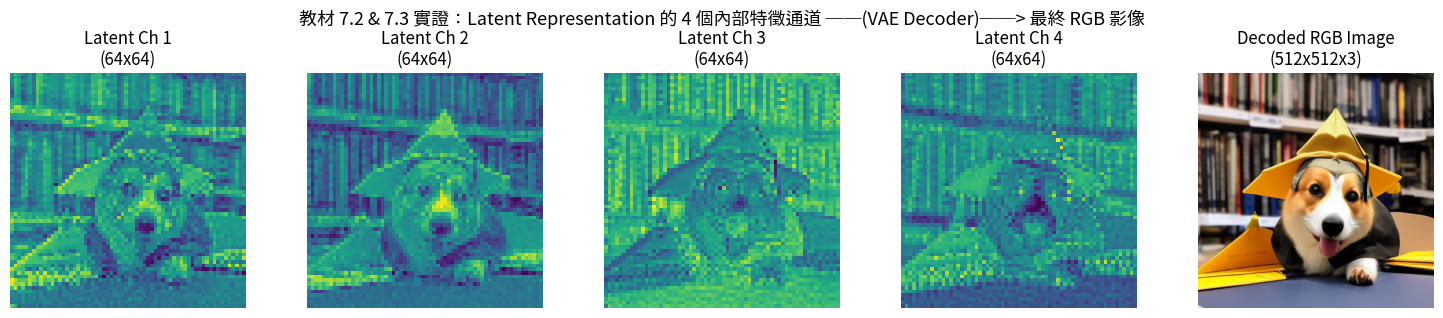

In [7]:
# @title Lab 1.5｜親眼觀察 VAE 的 Encoder 與 Decoder：進入 Latent Space 再回來！(7.1 ～ 7.3) { display-mode: "form" }
# @markdown 執行此區塊，我們會抽取出模型裡真正的 **VAE (Variational Autoencoder)**，把一張 `512×512×3` 的 RGB 影像編碼成 `64×64×4` 的 **Latent Representation**，並視覺化它的 4 個潛在通道（Channels）！

# 強制升級 torchao 以解決 diffusers 導入時 FqnToConfig 遺失的相容性錯誤
import sys
try:
    from diffusers import StableDiffusionPipeline
except (ImportError, RuntimeError) as e:
    print("⚠️ 偵測到 torchao / diffusers 套件版本衝突，正在強制升級 torchao...")
    !pip install -q -U torchao
    print("✅ 升級完成！即將嘗試繼續執行...")

import torch
import numpy as np
import matplotlib.pyplot as plt

# 額外安全防範：若重啟 Runtime 後未執行 Step 0，在此進行自動補載入宣告
try:
    get_diffusion_pipe
except NameError:
    print("ℹ️ 偵測到記憶體中遺失 get_diffusion_pipe 宣告，正在自動重載定義...")
    _GLOBAL_PIPE = None
    _CURRENT_MODEL_ID = None
    def get_diffusion_pipe(model_id: str = "runwayml/stable-diffusion-v1-5"):
        global _GLOBAL_PIPE, _CURRENT_MODEL_ID
        if _GLOBAL_PIPE is None or _CURRENT_MODEL_ID != model_id:
            from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler
            device = "cuda" if torch.cuda.is_available() else "cpu"
            dtype = torch.float16 if device == "cuda" else torch.float32
            print(f"⏳ 正在載入真實 Latent Diffusion 模型：{model_id} (Device: {device}, Dtype: {dtype})...")
            pipe = StableDiffusionPipeline.from_pretrained(
                model_id,
                torch_dtype=dtype,
                safety_checker=None
            )
            pipe.scheduler = EulerDiscreteScheduler.from_config(pipe.scheduler.config)
            pipe = pipe.to(device)
            _GLOBAL_PIPE = pipe
            _CURRENT_MODEL_ID = model_id
            print("✅ 模型載入完成！包含 Text Encoder (CLIP)、UNet (Cross-Attention) 與 VAE (Encoder/Decoder)。")
        return _GLOBAL_PIPE

if torch.cuda.is_available():
    pipe = get_diffusion_pipe()
    vae = pipe.vae
    device = pipe.device
    dtype = pipe.dtype

    # 先快速生成一張基礎圖或建立測試影像
    gen = torch.Generator(device=device).manual_seed(42)
    with torch.no_grad():
        # 1. 在 Latent Space 中執行 Denoising，但先要求輸出 "latent" 而非解碼後的圖片！
        latent_tensor = pipe(
            prompt=PROMPT_VERSIONS["V2"],
            num_inference_steps=20,
            guidance_scale=7.0,
            generator=gen,
            output_type="latent"
        ).images

        # 2. 手動透過 VAE Decoder 將 Latent 轉回 Pixel Space RGB Image
        decoded = vae.decode(latent_tensor / vae.config.scaling_factor, return_dict=False)[0]
        rgb_img = pipe.image_processor.postprocess(decoded, output_type="pil")[0]

    print(f"📐 1. 生成過程中的 Latent Tensor 形狀 : {tuple(latent_tensor.shape)} -> 共 {latent_tensor.numel():,} 個數值")
    print(f"📐 2. 經 Decoder 還原後的 RGB 影像尺寸 : {rgb_img.size} x 3 Channels -> 共 {rgb_img.width * rgb_img.height * 3:,} 個數值")
    print(f"💡 驗證結論：在 Latent Space 中執行去噪，運算資料量足足縮小了 {(rgb_img.width * rgb_img.height * 3) / latent_tensor.numel():.0f} 倍！\n")

    # 視覺化 4 個 Latent Channels vs 最終解碼出的 RGB Image
    lat_np = latent_tensor[0].detach().cpu().float().numpy()
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
    for ch in range(4):
        axes[ch].imshow(lat_np[ch], cmap="viridis")
        axes[ch].set_title(f"Latent Ch {ch+1}\n(64x64)")
        axes[ch].axis("off")
    axes[4].imshow(rgb_img)
    axes[4].set_title("Decoded RGB Image\n(512x512x3)")
    axes[4].axis("off")
    plt.suptitle("教材 7.2 & 7.3 實證：Latent Representation 的 4 個內部特徵通道 ──(VAE Decoder)──> 最終 RGB 影像", fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print("💡 若要執行本區塊親眼拆解 VAE Latent Tensor，請先開啟 Colab 的免費 T4 GPU！")

In [8]:
# @title Lab 2｜為什麼 Cache Key 不能只有 Prompt？建立 Experiment Hash 與 Generation Manifest (7.13 & 7.23) { display-mode: "form" }
# @markdown 執行此區塊，直接比較「只 Hash Prompt（錯誤做法）」與「Hash 完整 Config（正確做法）」在遇到不同 Seed 時的差異！

def make_bad_cache_key(config: dict) -> str:
    """❌ 錯誤示範：只拿 Prompt 計算 Hash"""
    return hashlib.sha256(config["prompt"].encode("utf-8")).hexdigest()[:12]

def make_experiment_hash(config: dict) -> str:
    """✅ 正確示範 (教材 7.23)：將所有影響生成結果的參數排序序列化後計算 SHA-256"""
    core_keys = [
        "model", "revision", "prompt", "negative_prompt",
        "seed", "width", "height", "steps", "scheduler", "guidance_scale"
    ]
    filtered = {k: config.get(k) for k in core_keys}
    text = json.dumps(filtered, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:12]

exp_run_1 = {
    "model": "edu-latent-sim-v1",
    "revision": "2026.10",
    "prompt": PROMPT_VERSIONS["V3"],
    "negative_prompt": None,
    "seed": 42,
    "width": 512,
    "height": 512,
    "steps": 30,
    "scheduler": "euler_discrete",
    "guidance_scale": 7.0
}

exp_run_2 = dict(exp_run_1)
exp_run_2["seed"] = 999  # 同一句 Prompt，但改了 Seed！

print("❌ 【如果 Cache Key 只看 Prompt】")
print(f"  • Seed 42  的檔名: {make_bad_cache_key(exp_run_1)}.png")
print(f"  • Seed 999 的檔名: {make_bad_cache_key(exp_run_2)}.png  <-- 糟糕！Hash 完全一樣，實驗二會直接誤用舊快取或覆蓋檔案！\n")

print("✅ 【如果 Cache Key 包含完整 Generation Config (教材 7.23 標準做法)】")
id_1 = make_experiment_hash(exp_run_1)
id_2 = make_experiment_hash(exp_run_2)
print(f"  • Seed 42  的 Experiment ID: {id_1}  --> outputs/{id_1}.png + metadata/{id_1}.json")
print(f"  • Seed 999 的 Experiment ID: {id_2}  --> outputs/{id_2}.png + metadata/{id_2}.json\n")

# 示範產生一份標準的 Generation Manifest (教材 7.13)
sample_manifest = dict(exp_run_1)
sample_manifest["experiment_id"] = id_1
sample_manifest["date"] = datetime.now().isoformat(timespec="seconds")
sample_manifest["library_version"] = "educational-sandbox-1.0 / Pillow"

print("📄 【標準 Generation Manifest (JSON) 範例】:")
print(json.dumps(sample_manifest, indent=2, ensure_ascii=False))

❌ 【如果 Cache Key 只看 Prompt】
  • Seed 42  的檔名: b4032be0bb71.png
  • Seed 999 的檔名: b4032be0bb71.png  <-- 糟糕！Hash 完全一樣，實驗二會直接誤用舊快取或覆蓋檔案！

✅ 【如果 Cache Key 包含完整 Generation Config (教材 7.23 標準做法)】
  • Seed 42  的 Experiment ID: eb1b20746991  --> outputs/eb1b20746991.png + metadata/eb1b20746991.json
  • Seed 999 的 Experiment ID: 114e88f3f27c  --> outputs/114e88f3f27c.png + metadata/114e88f3f27c.json

📄 【標準 Generation Manifest (JSON) 範例】:
{
  "model": "edu-latent-sim-v1",
  "revision": "2026.10",
  "prompt": "a corgi wearing a red graduation cap, sitting in front of a university library, centered composition, eye-level camera, soft afternoon light, flat editorial illustration",
  "negative_prompt": null,
  "seed": 42,
  "width": 512,
  "height": 512,
  "steps": 30,
  "scheduler": "euler_discrete",
  "guidance_scale": 7.0,
  "experiment_id": "eb1b20746991",
  "date": "2026-10-21T08:09:22",
  "library_version": "educational-sandbox-1.0 / Pillow"
}


✅ 四格實驗完成！已自動產生 Contact Sheet：experiment_07/outputs/comparison_seed.png


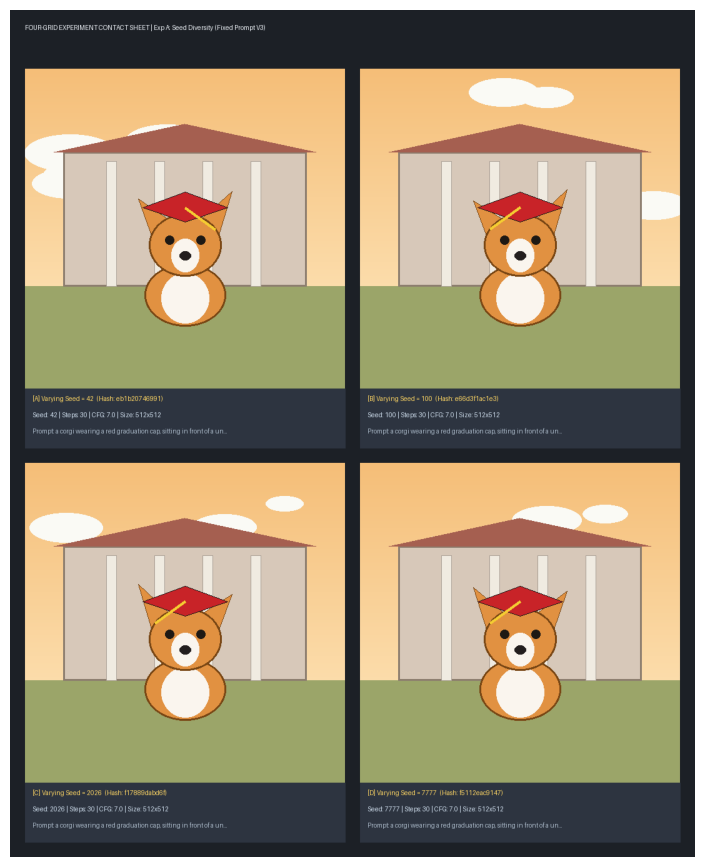

In [12]:
# @title Lab 3｜四格控制變因實驗室 ＆ 自動建立 Contact Sheet (7.14 ～ 7.17 + 延伸挑戰三) { display-mode: "form" }
# @markdown 請從下拉選單切換三種經典的「單一變因控制實驗」，系統會自動生成四格圖片、配對儲存 `metadata/*.json`，並將結果合成為 `comparison.png`！

選擇實驗模式 = "實驗 A｜Seed 多樣性實驗 (固定 Prompt V3, 只改 4 個 Seeds)" # @param ["實驗 A｜Seed 多樣性實驗 (固定 Prompt V3, 只改 4 個 Seeds)", "實驗 B｜Guidance Sweep 實驗 (固定 Seed=42, 只改 CFG=1, 5, 8, 18)", "實驗 C｜Prompt 版本演進 A/B/C/D 測試 (固定 Seed=42, 只改 Prompt V1~V4)"]
啟用_Pillow_精確文字排版覆蓋 = False # @param {type:"boolean"}

def run_single_experiment(config: dict, label_title: str) -> tuple[Image.Image, dict]:
    exp_id = make_experiment_hash(config)
    img_path = OUTPUTS_DIR / f"{exp_id}.png"
    meta_path = METADATA_DIR / f"{exp_id}.json"

    img = simulate_conditional_generation(config)

    # 對應教材 7.17：當文字是正式資訊時，使用 Pillow 進行可控、可驗證的後期排版
    if 啟用_Pillow_精確文字排版覆蓋:
        draw = ImageDraw.Draw(img)
        draw.rectangle([20, 20, 492, 68], fill=(20, 35, 60))
        draw.text((35, 34), "NUTC MULTIMEDIA LAB | VERIFIED TEXT 2026", fill=(255, 230, 120))

    img.save(img_path)

    manifest = dict(config)
    manifest["experiment_id"] = exp_id
    manifest["label"] = label_title
    manifest["output_file"] = str(img_path)
    manifest["date"] = datetime.now().isoformat(timespec="seconds")
    meta_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    return img, manifest

def build_contact_sheet(results: list[tuple[Image.Image, dict]], sheet_title: str, out_filename: str) -> Path:
    """延伸挑戰三：自動讀取圖片與 Metadata，排列成 2x2 Contact Sheet 並標註實驗參數"""
    cell_w, cell_h = 512, 512
    caption_h = 95
    header_h = 70
    pad = 24

    sheet_w = pad * 3 + cell_w * 2
    sheet_h = header_h + pad * 3 + (cell_h + caption_h) * 2
    sheet = Image.new("RGB", (sheet_w, sheet_h), (28, 32, 38))
    draw = ImageDraw.Draw(sheet)

    draw.text((pad, 22), f"FOUR-GRID EXPERIMENT CONTACT SHEET | {sheet_title}", fill=(240, 245, 250))

    for idx, (img, meta) in enumerate(results[:4]):
        row = idx // 2
        col = idx % 2
        x0 = pad + col * (cell_w + pad)
        y0 = header_h + pad + row * (cell_h + caption_h + pad)

        sheet.paste(img.resize((cell_w, cell_h)), (x0, y0))
        draw.rectangle([x0, y0 + cell_h, x0 + cell_w, y0 + cell_h + caption_h], fill=(45, 52, 64))

        line1 = f"[{chr(65+idx)}] {meta['label']}  (Hash: {meta['experiment_id']})"
        line2 = f"Seed: {meta['seed']} | Steps: {meta['steps']} | CFG: {meta['guidance_scale']} | Size: {meta['width']}x{meta['height']}"
        prompt_short = meta['prompt'][:62] + ("..." if len(meta['prompt']) > 62 else "")
        line3 = f"Prompt: {prompt_short}"

        draw.text((x0 + 12, y0 + cell_h + 10), line1, fill=(255, 215, 100))
        draw.text((x0 + 12, y0 + cell_h + 36), line2, fill=(210, 225, 240))
        draw.text((x0 + 12, y0 + cell_h + 62), line3, fill=(170, 185, 200))

    out_path = OUTPUTS_DIR / out_filename
    sheet.save(out_path)
    return out_path

base_cfg = {
    "model": "edu-latent-sim-v1",
    "revision": "2026.10",
    "prompt": PROMPT_VERSIONS["V3"],
    "negative_prompt": None,
    "seed": 42,
    "width": 512,
    "height": 512,
    "steps": 30,
    "scheduler": "euler_discrete",
    "guidance_scale": 7.0
}

experiment_results = []

if "實驗 A" in 選擇實驗模式:
    for s in [42, 100, 2026, 7777]:
        c = dict(base_cfg)
        c["seed"] = s
        experiment_results.append(run_single_experiment(c, f"Varying Seed = {s}"))
    sheet_path = build_contact_sheet(experiment_results, "Exp A: Seed Diversity (Fixed Prompt V3)", "comparison_seed.png")

elif "實驗 B" in 選擇實驗模式:
    for g in [1.0, 5.0, 8.0, 18.0]:
        c = dict(base_cfg)
        c["guidance_scale"] = g
        experiment_results.append(run_single_experiment(c, f"Varying Guidance (CFG) = {g}"))
    sheet_path = build_contact_sheet(experiment_results, "Exp B: Guidance Sweep (Fixed Seed=42)", "comparison_guidance.png")

else:
    for ver in ["V1", "V2", "V3", "V4"]:
        c = dict(base_cfg)
        c["prompt"] = PROMPT_VERSIONS[ver]
        experiment_results.append(run_single_experiment(c, f"Prompt {ver}"))
    sheet_path = build_contact_sheet(experiment_results, "Exp C: Prompt Version History (Fixed Seed=42)", "comparison_prompt.png")

print(f"✅ 四格實驗完成！已自動產生 Contact Sheet：{sheet_path}")
plt.figure(figsize=(11, 11))
plt.imshow(Image.open(sheet_path))
plt.axis("off")
plt.show()

  ⚡ [快取命中] 直接載入已生成的真實影像：2ec847b3a3ff.png (Seed = 42)
  ⚡ [快取命中] 直接載入已生成的真實影像：f8fa9fdc0f26.png (Seed = 100)
  ⚡ [快取命中] 直接載入已生成的真實影像：12e6844eadd9.png (Seed = 2026)
  ⚡ [快取命中] 直接載入已生成的真實影像：4f3219a9fe74.png (Seed = 7777)

🎉 實驗完成！四格比較圖已儲存至：experiment_07/outputs/comparison_seed.png


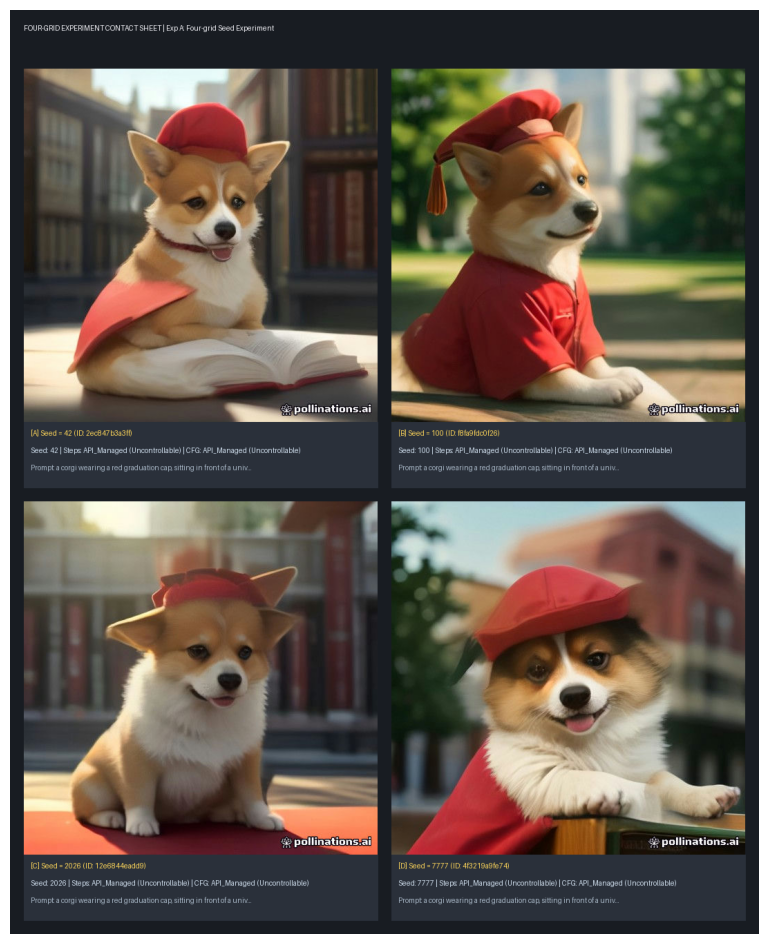

In [13]:
# @title Lab 3｜【真實生成影像】四格控制變因實驗室 ＆ 自動產出 Manifest 與 Contact Sheet (7.14 ～ 7.23) { display-mode: "form" }
# @markdown 請選擇「生成引擎模式」與「控制變因實驗主題」：
# @markdown - **模式 1 (本地 Diffusers GPU)**：使用真正的 Stable Diffusion v1.5，完整支援 Seed、Steps、Guidance Scale (CFG) 與 Negative Prompt 控制！
# @markdown - **模式 2 (雲端真實 AI API - 免 GPU)**：使用 HTTP Request 搭配 Timeout 與錯誤處理（教材 7.22），呼叫線上 Flux/SD 生成真實圖片（注意：線上 API 僅支援控制 Prompt 與 Seed，Guidance 由雲端固定，正好體現教材 **7.19 線上服務的實驗限制**！）。

生成引擎模式 = "模式 2：雲端真實 AI 生成 API (免 GPU / 支援 Seed 與 Prompt)" # @param ["模式 1：本地真實 Latent Diffusion (需開啟 Colab T4 GPU)", "模式 2：雲端真實 AI 生成 API (免 GPU / 支援 Seed 與 Prompt)"]
選擇實驗主題 = "實驗 A｜Four-grid Seed Experiment (固定 Prompt V3, 只改 4 個 Seeds)" # @param ["實驗 A｜Four-grid Seed Experiment (固定 Prompt V3, 只改 4 個 Seeds)", "實驗 B｜Guidance Sweep 實驗 (固定 Seed=42, 只改 CFG = 1.5, 5.0, 7.5, 16.0)", "實驗 C｜Prompt Version A/B/C/D 比較 (固定 Seed=42, 比較 Prompt V1 ~ V4)"]
使用快取_若已生成過則直接讀取 = True # @param {type:"boolean"}

def generate_real_image_and_manifest(config: dict, label_title: str, engine_mode: str) -> tuple[Image.Image, dict]:
    """真正執行 AI 影像生成，並同步建立成對的 {hash}.png 與 {hash}.json (Generation Manifest)"""
    exp_id = make_experiment_hash(config)
    img_path = OUTPUTS_DIR / f"{exp_id}.png"
    meta_path = METADATA_DIR / f"{exp_id}.json"

    # 快取檢查 (教材 7.23)
    if 使用快取_若已生成過則直接讀取 and img_path.exists() and meta_path.exists():
        print(f"  ⚡ [快取命中] 直接載入已生成的真實影像：{img_path.name} ({label_title})")
        img = Image.open(img_path).convert("RGB")
        manifest = json.loads(meta_path.read_text(encoding="utf-8"))
        return img, manifest

    print(f"  🎨 [開始生成] {label_title} | Seed={config['seed']} | CFG={config['guidance_scale']} ...")
    t0 = time.time()

    if "模式 1" in engine_mode:
        if not torch.cuda.is_available():
            raise RuntimeError("您選擇了『模式 1 (本地 GPU)』，但目前未開啟 GPU！請改選『模式 2 (雲端 API)』或開啟 T4 GPU。")
        pipe = get_diffusion_pipe(config["model"])
        generator = torch.Generator(device=pipe.device).manual_seed(int(config["seed"]))
        img = pipe(
            prompt=config["prompt"],
            negative_prompt=config.get("negative_prompt"),
            num_inference_steps=int(config["steps"]),
            guidance_scale=float(config["guidance_scale"]),
            width=int(config["width"]),
            height=int(config["height"]),
            generator=generator
        ).images[0]
        uncontrolled_factors = ["cross_platform_gpu_determinism"]
    else:
        # 模式 2：透過 HTTP Request (教材 7.22) 呼叫免金鑰雲端生成服務，實測教材 7.19 線上服務限制
        import urllib.parse
        encoded_prompt = urllib.parse.quote(config["prompt"])
        url = f"https://image.pollinations.ai/prompt/{encoded_prompt}?width={config['width']}&height={config['height']}&seed={config['seed']}&nologo=true"
        resp = requests.get(url, timeout=120)
        resp.raise_for_status()
        img = Image.open(BytesIO(resp.content)).convert("RGB")
        # 依教材 7.19：誠實記錄線上服務無法控制的變因
        config["guidance_scale"] = "API_Managed (Uncontrollable)"
        config["steps"] = "API_Managed (Uncontrollable)"
        config["scheduler"] = "API_Managed (Uncontrollable)"
        uncontrolled_factors = ["guidance_scale", "steps", "scheduler", "server_model_revision"]

    elapsed = round(time.time() - t0, 2)
    img.save(img_path)

    # 建立教材 7.13 的完整 Generation Manifest
    manifest = {
        **config,
        "experiment_id": exp_id,
        "label": label_title,
        "output_file": str(img_path),
        "generation_time_sec": elapsed,
        "uncontrolled_variables": uncontrolled_factors,
        "date": datetime.now().isoformat(timespec="seconds"),
        "torch_version": torch.__version__,
        "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU / Cloud_API"
    }
    meta_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"     ✅ 生成成功！耗時 {elapsed}s -> 已保存 {img_path.name} 與 {meta_path.name}")
    return img, manifest

def create_contact_sheet(results: list[tuple[Image.Image, dict]], title: str, filename: str) -> Path:
    """對應教材延伸挑戰三：自動讀取 outputs 與 metadata，合成 2x2 實驗報告圖"""
    w, h = 512, 512
    cap_h, head_h, pad = 95, 65, 20
    sheet = Image.new("RGB", (pad*3 + w*2, head_h + pad*3 + (h + cap_h)*2), (24, 28, 34))
    draw = ImageDraw.Draw(sheet)
    draw.text((pad, 20), f"FOUR-GRID EXPERIMENT CONTACT SHEET | {title}", fill=(245, 245, 250))

    for i, (im, meta) in enumerate(results[:4]):
        r, c = i // 2, i % 2
        x0, y0 = pad + c * (w + pad), head_h + pad + r * (h + cap_h + pad)
        sheet.paste(im.resize((w, h)), (x0, y0))
        draw.rectangle([x0, y0 + h, x0 + w, y0 + h + cap_h], fill=(42, 48, 58))
        draw.text((x0 + 10, y0 + h + 10), f"[{chr(65+i)}] {meta['label']} (ID: {meta['experiment_id']})", fill=(255, 215, 90))
        draw.text((x0 + 10, y0 + h + 35), f"Seed: {meta['seed']} | Steps: {meta['steps']} | CFG: {meta['guidance_scale']}", fill=(210, 225, 240))
        p_short = meta['prompt'][:64] + ("..." if len(meta['prompt']) > 64 else "")
        draw.text((x0 + 10, y0 + h + 60), f"Prompt: {p_short}", fill=(170, 185, 200))

    out_p = OUTPUTS_DIR / filename
    sheet.save(out_p)
    return out_p

# 設定基準控制變因 (Baseline)
base_config = {
    "model": "runwayml/stable-diffusion-v1-5" if "模式 1" in 生成引擎模式 else "cloud-flux-api",
    "revision": "fp16" if torch.cuda.is_available() else "cloud-latest",
    "prompt": PROMPT_VERSIONS["V3"],
    "negative_prompt": "blurry, watermark, low quality, deformed",
    "seed": 42,
    "width": 512,
    "height": 512,
    "steps": 25,
    "scheduler": "EulerDiscreteScheduler",
    "guidance_scale": 7.5
}

results_list = []

if "實驗 A" in 選擇實驗主題:
    for s in [42, 100, 2026, 7777]:
        cfg = {**base_config, "seed": s}
        results_list.append(generate_real_image_and_manifest(cfg, f"Seed = {s}", 生成引擎模式))
    sheet_file = create_contact_sheet(results_list, "Exp A: Four-grid Seed Experiment", "comparison_seed.png")

elif "實驗 B" in 選擇實驗主題:
    for g in [1.5, 5.0, 7.5, 16.0]:
        cfg = {**base_config, "guidance_scale": g}
        results_list.append(generate_real_image_and_manifest(cfg, f"Guidance (CFG) = {g}", 生成引擎模式))
    sheet_file = create_contact_sheet(results_list, "Exp B: Guidance Scale Sweep", "comparison_guidance.png")

else:
    for ver in ["V1", "V2", "V3", "V4"]:
        cfg = {**base_config, "prompt": PROMPT_VERSIONS[ver]}
        results_list.append(generate_real_image_and_manifest(cfg, f"Prompt {ver}", 生成引擎模式))
    sheet_file = create_contact_sheet(results_list, "Exp C: Prompt Version Evolution", "comparison_prompt.png")

print(f"\n🎉 實驗完成！四格比較圖已儲存至：{sheet_file}")
plt.figure(figsize=(12, 12))
plt.imshow(Image.open(sheet_file))
plt.axis("off")
plt.show()

---
## Lab 4｜第三道防線【踹】：批次生成工程防禦戰（7.20 ～ 7.24）

當我們要執行 `4 Seeds × 4 Prompts × 4 Parameters` 的批次生成時，不能只寫一個裸奔的 `for` 迴圈！
實務上必須處理：
1. **API Key 環境變數管理（7.21）**：使用 `os.environ.get("IMAGE_API_KEY")`，絕不寫死在程式碼中 Commit 上傳。
2. **Experiment Hash 快取檢查（7.23）**：若 `outputs/{hash}.png` 與 `metadata/{hash}.json` 已經存在，直接讀取快取，省時又省錢！
3. **Timeout 與 Exponential Backoff 指數退避重試（7.22 & 7.24）**：遇到 `429 Rate Limit` 或網路超時，等待時間依 $1\text{s} \to 2\text{s} \to 4\text{s}$ 指數增加，而非高速狂刷伺服器。

In [14]:
# @title Lab 4｜測試批次生成的「快取命中」與「Exponential Backoff 抗 429 風暴」 { display-mode: "form" }
模擬伺服器不穩定率 = 0.4 # @param {type:"slider", min:0.0, max:0.8, step:0.1}
啟用_Hash快取機制 = True # @param {type:"boolean"}
啟用_Exponential_Backoff重試 = True # @param {type:"boolean"}

# 設定模擬環境變數 (教材 7.21)
os.environ["IMAGE_API_KEY"] = "edu_mock_key_safe_in_env_999"

class MockRateLimitError(Exception):
    pass

def mock_remote_api_call(config: dict, fail_prob: float, rng: np.random.Generator) -> Image.Image:
    """模擬可能拋出 HTTP 429 Too Many Requests 的線上生成服務"""
    api_key = os.environ.get("IMAGE_API_KEY")
    if not api_key:
        raise RuntimeError("Missing IMAGE_API_KEY in environment variables!")
    if rng.random() < fail_prob:
        raise MockRateLimitError("HTTP 429 Too Many Requests (Rate Limit Exceeded)")
    return simulate_conditional_generation(config)

def robust_batch_generate(configs: list[dict], use_cache: bool = True, use_backoff: bool = True):
    rng = np.random.default_rng(2026)
    cache_hits = 0
    api_calls = 0
    success = 0

    for idx, cfg in enumerate(configs, start=1):
        exp_id = make_experiment_hash(cfg)
        img_path = OUTPUTS_DIR / f"{exp_id}.png"
        meta_path = METADATA_DIR / f"{exp_id}.json"

        print(f"\n▶ [任務 {idx}/{len(configs)}] Experiment ID: {exp_id} (Seed={cfg['seed']}, CFG={cfg['guidance_scale']})")

        # 1. 檢查快取 (Cache Check)
        if use_cache and img_path.exists() and meta_path.exists():
            cache_hits += 1
            success += 1
            print(f"  ⚡ [CACHE HIT] 發現既有成果 {img_path.name} 與 Manifest，直接跳過重複生成！")
            continue

        # 2. 發送請求並搭配 Exponential Backoff
        max_retries = 4 if use_backoff else 1
        for attempt in range(1, max_retries + 1):
            try:
                api_calls += 1
                img = mock_remote_api_call(cfg, 模擬伺服器不穩定率, rng)
                img.save(img_path)
                manifest = dict(cfg)
                manifest["experiment_id"] = exp_id
                manifest["date"] = datetime.now().isoformat(timespec="seconds")
                meta_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
                print(f"  ✅ [API SUCCESS] 第 {attempt} 次嘗試成功！已寫入 {img_path.name}")
                success += 1
                break
            except MockRateLimitError as e:
                if not use_backoff or attempt == max_retries:
                    print(f"  💥 [FAILED] 遭遇錯誤且無重試機制（或已達上限）：{e}")
                else:
                    wait_sec = 0.4 * (2 ** (attempt - 1))  # 教學加速版 Exponential Backoff
                    print(f"  ⏳ [RETRY {attempt}/{max_retries-1}] 遭遇 {e} -> 執行 Exponential Backoff 等待 {wait_sec:.1f} 秒...")
                    time.sleep(wait_sec)

    print("\n" + "=" * 65)
    print(f"📊 【批次工程統計】總任務：{len(configs)} | 成功完成：{success} | 快取命中省下請求：{cache_hits} 次 | 實際呼叫 API：{api_calls} 次")
    print("=" * 65)

# 準備 4 個批次任務（前 2 個已在 Lab 3 產生過，用來驗證 Cache Hit；後 2 個為新參數）
batch_tasks = [
    {**base_cfg, "seed": 42, "guidance_scale": 7.0},
    {**base_cfg, "seed": 100, "guidance_scale": 7.0},
    {**base_cfg, "seed": 8888, "guidance_scale": 6.5},
    {**base_cfg, "seed": 9999, "guidance_scale": 9.0},
]

robust_batch_generate(batch_tasks, use_cache=啟用_Hash快取機制, use_backoff=啟用_Exponential_Backoff重試)


▶ [任務 1/4] Experiment ID: eb1b20746991 (Seed=42, CFG=7.0)
  ⚡ [CACHE HIT] 發現既有成果 eb1b20746991.png 與 Manifest，直接跳過重複生成！

▶ [任務 2/4] Experiment ID: e66d3f1ac1e3 (Seed=100, CFG=7.0)
  ⚡ [CACHE HIT] 發現既有成果 e66d3f1ac1e3.png 與 Manifest，直接跳過重複生成！

▶ [任務 3/4] Experiment ID: e215df58c160 (Seed=8888, CFG=6.5)
  ⏳ [RETRY 1/3] 遭遇 HTTP 429 Too Many Requests (Rate Limit Exceeded) -> 執行 Exponential Backoff 等待 0.4 秒...
  ✅ [API SUCCESS] 第 2 次嘗試成功！已寫入 e215df58c160.png

▶ [任務 4/4] Experiment ID: 707257dacb20 (Seed=9999, CFG=9.0)
  ✅ [API SUCCESS] 第 1 次嘗試成功！已寫入 707257dacb20.png

📊 【批次工程統計】總任務：4 | 成功完成：4 | 快取命中省下請求：2 次 | 實際呼叫 API：3 次


---
## Step 2｜課堂驗收與實驗紀錄單（對應教材基礎練習 1～3 & 檢核題）

請雙擊此區塊，根據你在上方 **Lab 1 ～ Lab 4** 觀察到的實際證據填寫答案：

### 📝 實驗觀察報告
1. **【Four-grid Seed Experiment】** 在實驗 A 中，固定了 Prompt V3 與其他參數，只改變 4 個 Seeds。請問畫面中**哪些視覺特徵保持穩定**？**哪些細節隨 Seed 改變**？
   - 答：
2. **【Guidance Sweep】** 在實驗 B 中，當 `Guidance Scale (CFG)` 分別設為 `1.0`、`8.0` 與 `18.0` 時，畫面分別出現什麼現象？為什麼說 **Guidance Scale 不是「品質旋鈕」**？
   - 答：
3. **【Prompt Version 與文字排版】** 在實驗 C 的 `Prompt V4` 中，模型直接生成的舉牌文字是否 100% 可靠？為什麼製作正式活動海報時，教材建議採用「**AI 生成背景視覺素材 ＋ Pillow / 設計工具壓印正式文字**」？
   - 答：
4. **【工程可重現性與快取】** 為什麼即使固定了 `Prompt + Seed + Model`，跨不同電腦或不同线上服務仍不保證得到 100% 相同的圖片？如果使用的線上服務不提供 `Seed` 參數，實驗紀錄（Manifest）應該怎麼寫才符合科學誠實原則？
   - 答：

In [15]:
# @title Step 3｜【驗】自動化實驗室交付檢查器 (Technical Validation) { display-mode: "form" }
# @markdown 執行此區塊，自動檢查你的 `experiment_07/` 資料夾是否符合教材 7.25 的完整交付規格！

png_files = sorted(OUTPUTS_DIR.glob("*.png"))
json_files = sorted(METADATA_DIR.glob("*.json"))
prompt_files = sorted(PROMPTS_DIR.glob("*.txt"))
contact_sheets = [p for p in png_files if p.name.startswith("comparison_")]

print("🔍 正在執行《07｜潛在空間、提示控制與可重現比較》實驗交付自動驗收...\n")
print(f"  1. Prompts 版本紀錄檔數量 : {len(prompt_files)} 份 ({'✅ 通過' if len(prompt_files) >= 3 else '❌ 未達標'})")
print(f"  2. Outputs 圖片總數量     : {len(png_files)} 張 ({'✅ 通過' if len(png_files) >= 4 else '❌ 未達標'})")
print(f"  3. Metadata JSON 總數量   : {len(json_files)} 份 ({'✅ 通過' if len(json_files) >= 4 else '❌ 未達標'})")
print(f"  4. Four-grid Contact Sheet: {len(contact_sheets)} 張 ({[p.name for p in contact_sheets]})")

# 檢查每個 JSON 是否包含必要欄位
required_fields = {"model", "prompt", "seed", "width", "height", "date", "experiment_id"}
valid_json_count = 0
for jf in json_files:
    data = json.loads(jf.read_text(encoding="utf-8"))
    if required_fields.issubset(data.keys()):
        valid_json_count += 1

print(f"  5. Manifest 欄位完整性檢查: {valid_json_count}/{len(json_files)} 份符合規範 ({'✅ 100% 通過' if valid_json_count == len(json_files) and len(json_files) > 0 else '⚠️ 請檢查欄位'})")

🔍 正在執行《07｜潛在空間、提示控制與可重現比較》實驗交付自動驗收...

  1. Prompts 版本紀錄檔數量 : 4 份 (✅ 通過)
  2. Outputs 圖片總數量     : 11 張 (✅ 通過)
  3. Metadata JSON 總數量   : 10 份 (✅ 通過)
  4. Four-grid Contact Sheet: 1 張 (['comparison_seed.png'])
  5. Manifest 欄位完整性檢查: 10/10 份符合規範 (✅ 100% 通過)
